# Checking the operational details

## Preamble

In [1]:
!cd ../../.. && pip install -v . --group=dev --group=observability --group=analysis

Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
Processing ./.
  Running command installing build dependencies
  Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/5d/40/e1e72872c6354b306daef1703549e8e83b4d43cfea356311bf722a043752/setuptools-83.0.0-py3-none-any.whl.metadata
    Using cached setuptools-83.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached setuptools-83.0.0-py3-none-any.whl (1.0 MB)
  ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
  torch 2.12.0 requires setuptools<82, but you have setuptools 83.0.0 which is incompatible.
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  r

In [2]:
import warnings

In [3]:
from lxml import etree
import apted

In [4]:
import massi.agents.tools as matls

In [5]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

In [6]:
from sklearn.metrics.pairwise import cosine_similarity
COS_SIMILARITY_READY = False
try:
    # NOTE: this can not run natively on Intel mac anymore
    from sentence_transformers import SentenceTransformer
    COS_SIMILARITY_READY = True
except ImportError as e:
    COS_SIMILARITY_READY = False
    warnings.warn("FAILED TO IMPORT `sentence_transformers`")
    warnings.warn(str(e))
finally:
    print(f"{COS_SIMILARITY_READY=}")

COS_SIMILARITY_READY=True


In [7]:
import tol_colors as tcls

In [8]:
import itertools as itlx
import json
from pathlib import Path
import re 

In [9]:
from typing import TypedDict, Any

In [10]:
from IPython.display import display, display_markdown

In [11]:
from pprint import pprint

In [12]:
tcls.set_default_colors()
plt.set_cmap(mpl.cm.tab20)

New config line: axes.prop_cycle : cycler('color', ['4477AA', 'EE6677', '228833', 'CCBB44', '66CCEE', 'AA3377', 'BBBBBB'])
Injecting line in file '/Users/mitjaorlov/.matplotlib/matplotlibrc'


<Figure size 640x480 with 0 Axes>

### Utilities

In [13]:
from warnings import warn

class OutcomeContainer[T](TypedDict):
    value: T | None
    error: str | None

def do_or_error(func) -> OutcomeContainer[Any]: 
    def wrapper(*args, **kwargs):
        try:
            return {"value": func(*args, **kwargs), "error": None}
        except Exception as e:
            return {"error": f"{type(e)}: {str(e)}", "value": None}
    return wrapper

def do_on_value(func):
    def wrapper(c: OutcomeContainer[Any], *args, **kwargs):
        if c["value"] is not None:
            return func(c["value"], *args, **kwargs)
        else:
            return c
    return wrapper

In [14]:
EXPERIMENT_BASE_DIR = "../../../_data/gbif_data_archive/"

def grounded_path(suffix: str | Path) -> Path:
    return Path(EXPERIMENT_BASE_DIR) / suffix

In [15]:
def ok_results(df):
    return df[df["success"]]

### Constructs

In [16]:
@do_or_error
def parse_xml_file(path: str | Path):
    return etree.parse(path)

@do_or_error
def parse_xml_string(data: str):
    return etree.fromstring(data.encode())

@do_on_value
def parse_xml_content(xml_content: Any):
    return parse_xml_string(str(xml_content))

In [17]:
@do_or_error
def resolve_xml_content(r: dict) -> str:
    return r['resolutions'][0]['working_copy_xml_blueprint']["content"]    

In [18]:
@do_on_value
@do_or_error
def cleanup_gap_failures(xml_data:str):
    return re.sub(r"\{\{GAP_([0-9]+)[^\}]*\}+", r"not-derived-\1", xml_data)

@do_on_value
@do_or_error
def cleanup_special_characters(xml_data:str):
    return re.sub("&", "&amp;", xml_data)

In [19]:
class NodeInfo(TypedDict):
    tag: str
    degree: int
    depth: int
    is_leaf: bool # <=> (degree == 0) 
    attributes: str # <-- json.dumps(attributes)
    attributes_count: int # <-- |attributes.keys()|
    text: str
    path: str | None

class TreeInfo(TypedDict):
    size: int # <-- |_nodes|
    size_with_attributes: int # <-- SUM(n.attributes_count for n in _nodes)
    _nodes: list[NodeInfo]

def project_public(d: dict):
    public_data = {k:v for k,v in d.items() if not str(k).startswith("_")}
    return public_data

In [20]:
def get_root(tree):
    """Retrieves a root of the provided tree"""
    if hasattr(tree, "getroot"):
        return tree.getroot()
    return tree

In [21]:
@do_on_value
@do_or_error
def get_tree_info(tree) -> TreeInfo:
    return _get_tree_info(tree)

def _get_tree_info(tree) -> TreeInfo:
    root = etree.ElementTree(get_root(tree))
    
    def _get_node_info(node) -> NodeInfo:
        return {
            "tag": node.tag,
            "depth": len(list(node.iterancestors())),
            "degree": len(node),
            "is_leaf": len(node) == 0,
            "attributes": json.dumps(dict(node.attrib.items())),
            "attributes_count": len(node.attrib.keys()),
            "has_attributes": bool(node.attrib),
            "text": node.text,
            "has_text": bool(node.text.strip()) if node.text else False,
            "path": None if isinstance(node, etree._Comment) else root.getelementpath(node)
        }
    
    nodes_info = list(map(_get_node_info, root.iter()))
    return {
        "size": len(nodes_info), 
        "size_with_attributes": len(nodes_info) + sum(n["attributes_count"] for n in nodes_info),
        "_nodes": nodes_info
    }

## Data collection

In [22]:
gbif_cases = pd.read_csv("../../runtime/full_gbif_cases.csv")
experiment_results = pd.read_csv("../../runtime/experiment_cross_scenarios_cases.log.csv")

In [23]:
dwc_data_results = experiment_results[(experiment_results["schema"] == "dwc") & (experiment_results["strategy"] == "data-focus")]
dwc_author_results = experiment_results[(experiment_results["schema"] == "dwc") & (experiment_results["strategy"] == "author-focus")]

eml_data_results = experiment_results[(experiment_results["schema"] == "eml") & (experiment_results["strategy"] == "data-focus")]
eml_author_results = experiment_results[(experiment_results["schema"] == "eml") & (experiment_results["strategy"] == "author-focus")]

In [35]:
from pprint import pprint
import json

example_outcome = json.loads(dwc_data_results[dwc_data_results["case_id"] == 59]["outcome_json"].tolist()[0])

pprint(example_outcome)

{'dataset': {'csv_files': [{'details': {'column_count': 29,
                                        'dataframe_head': 'id,type,language,license,institutionID,collectionID,institutionCode,collectionCode,basisOfRecord,occurrenceID,catalogNumber,recordedBy,eventDate,continent,country,countryCode,stateProvince,locality,minimumElevationInMeters,maximumElevationInMeters,decimalLatitude,decimalLongitude,geodeticDatum,coordinateUncertaintyInMeters,verbatimIdentification,identifiedBy,scientificName,kingdom,taxonRank\n'
                                                          'TO-0006001,PhysicalObject,en|it,https://creativecommons.org/licenses/by-nc/4.0/legalcode,https://www.gbif.org/grscicoll/institution/229f1606-d58e-4316-8673-7e7c7fb3f2ef,https://www.gbif.org/grscicoll/collection/e567333a-119b-4640-a4cd-ccd89f71fe1f,UNITO,TO,PreservedSpecimen,TO-0006001,1,Deborah '
                                                          'Isocrono,1997-10-25,Europe,Italy,IT,Piemonte,"Valsesia, '
          

In [42]:
pprint(example_outcome["resolutions"][0]['verified_gap_derivation_plan'])
pprint(len(example_outcome["resolutions"][0]['verified_gap_derivation_plan']['gaps']))

{'gaps': [{'gap_derivation_request': '# Context\n'
                                     'You are deriving the `metadata` '
                                     'attribute value for a Darwin Core '
                                     'Archive `archive` element in '
                                     '`meta.xml`.\n'
                                     '\n'
                                     '# Current XML Context\n'
                                     '- Parent element: `<archive>`\n'
                                     '- Attribute to resolve: `metadata`\n'
                                     '- Blueprint placeholder: '
                                     '`{{GAP_001:URI:METADATA_LOCATION}}`\n'
                                     '\n'
                                     '# Goal\n'
                                     'Determine the correct URI/path to the '
                                     'archive metadata file location to be '
                                     'plac

## Exploring the plans

In [26]:
dwc_data_results["outcome_json_loaded"] = dwc_data_results["outcome_json"].apply(json.loads)
dwc_author_results["outcome_json_loaded"] = dwc_author_results["outcome_json"].apply(json.loads)

eml_data_results["outcome_json_loaded"] = eml_data_results["outcome_json"].apply(json.loads)
eml_author_results["outcome_json_loaded"] = eml_author_results["outcome_json"].apply(json.loads)

In [27]:
dwc_author_results["outcome_json_loaded"]

10     {'messages': [], 'settings': {'runtime_config'...
11     {'messages': [], 'settings': {'runtime_config'...
12     {'messages': [], 'settings': {'runtime_config'...
13     {'messages': [], 'settings': {'runtime_config'...
14     {'status': 'exception', 'error_content': ''res...
                             ...                        
351    {'messages': [], 'settings': {'runtime_config'...
352    {'messages': [], 'settings': {'runtime_config'...
353    {'messages': [], 'settings': {'runtime_config'...
442    {'messages': [], 'settings': {'runtime_config'...
445    {'messages': [], 'settings': {'runtime_config'...
Name: outcome_json_loaded, Length: 179, dtype: object

In [48]:
dwc_data_results["ops.resolution_count"] = dwc_data_results["outcome_json_loaded"].apply(lambda oj: len(oj["resolutions"] if "resolutions" in oj else []))
dwc_author_results["ops.resolution_count"] = dwc_author_results["outcome_json_loaded"].apply(lambda oj: len(oj["resolutions"] if "resolutions" in oj else []))

eml_data_results["ops.resolution_count"] = eml_data_results["outcome_json_loaded"].apply(lambda oj: len(oj["resolutions"] if "resolutions" in oj else []))
eml_author_results["ops.resolution_count"] = eml_author_results["outcome_json_loaded"].apply(lambda oj: len(oj["resolutions"] if "resolutions" in oj else []))

In [51]:
print(dwc_data_results["ops.resolution_count"].describe())
print(dwc_author_results["ops.resolution_count"].describe())

print(eml_data_results["ops.resolution_count"].describe())
print(eml_author_results["ops.resolution_count"].describe())

count    179.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
Name: ops.resolution_count, dtype: float64
count    179.000000
mean       0.977654
std        0.148222
min        0.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: ops.resolution_count, dtype: float64
count    179.000000
mean       0.865922
std        0.341692
min        0.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: ops.resolution_count, dtype: float64
count    179.000000
mean       0.882682
std        0.322702
min        0.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: ops.resolution_count, dtype: float64


In [52]:
def with_ok_resolutions(df):
    return df[df["ops.resolution_count"] > 0]

dwc_data_results["ops.plan_size"] = with_ok_resolutions(dwc_data_results)["outcome_json_loaded"].apply(lambda oj: len(oj["resolutions"][0]['verified_gap_derivation_plan']['gaps']))
dwc_author_results["ops.plan_size"] = with_ok_resolutions(dwc_author_results)["outcome_json_loaded"].apply(lambda oj: len(oj["resolutions"][0]['verified_gap_derivation_plan']['gaps']))

eml_data_results["ops.plan_size"] = with_ok_resolutions(eml_data_results)["outcome_json_loaded"].apply(lambda oj: len(oj["resolutions"][0]['verified_gap_derivation_plan']['gaps']))
eml_author_results["ops.plan_size"] = with_ok_resolutions(eml_author_results)["outcome_json_loaded"].apply(lambda oj: len(oj["resolutions"][0]['verified_gap_derivation_plan']['gaps']))

In [53]:
print(dwc_data_results["ops.plan_size"].describe())
print(dwc_author_results["ops.plan_size"].describe())

print(eml_data_results["ops.plan_size"].describe())
print(eml_author_results["ops.plan_size"].describe())

count    179.000000
mean       1.413408
std        2.227771
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max       25.000000
Name: ops.plan_size, dtype: float64
count    175.000000
mean       1.240000
std        1.465935
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max       17.000000
Name: ops.plan_size, dtype: float64
count    155.000000
mean      14.109677
std        3.504297
min        1.000000
25%       14.000000
50%       14.000000
75%       16.000000
max       24.000000
Name: ops.plan_size, dtype: float64
count    158.000000
mean      14.069620
std        3.078831
min        3.000000
25%       14.000000
50%       14.000000
75%       15.000000
max       23.000000
Name: ops.plan_size, dtype: float64


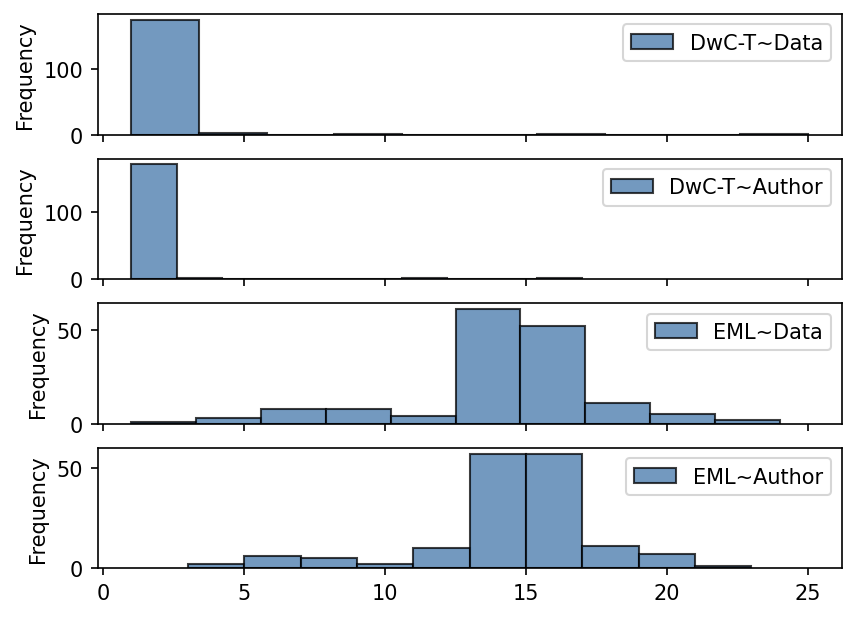

In [66]:
result_groups = {
    "DwC-T~Data": dwc_data_results,
    "DwC-T~Author": dwc_author_results,
    "EML~Data": eml_data_results,
    "EML~Author": eml_author_results,
}

fig, axs = plt.subplots(4,1, dpi=150, sharex=True)

for (k, df), ax in zip(result_groups.items(), axs):
    df["ops.plan_size"].plot.hist(label=k, legend=True, alpha=0.75, edgecolor="k", ax=ax)

In [81]:
eml_data_results[eml_data_results["case_id"] == 10]["success"]

374    True
Name: success, dtype: bool

In [83]:
import json
json.dumps(eml_data_results[eml_data_results["case_id"] == 10]["outcome_json_loaded"].tolist()[0])

'{"messages": [], "settings": {"runtime_config": {"output_directory": "_data/gbif_data_archive/out/c_10-x-s_8", "working_directory": "_data/gbif_data_archive/working_copy/data/011-a6d11393-94d2-3e38-a09e-da169cd7f1d9-download-data"}}, "goals": [{"level": 0, "scopes": ["descriptive", "administrative", "preservation", "use"], "target_filename": "eml.xml", "schema_source": "https://eml.ecoinformatics.org/eml-2.2.0/eml.xsd", "description": "This metadata file contains the dataset\'s aggregate metadata.This is a resource metadata document that provides information about the dataset itself such as a description (abstract) of the dataset, the agents responsible for authorship, publication and documentation, bibliographic and citation information, collection methods and much more.It is based on the Ecological Metadata Language.", "metadata_goal_key": "eml"}], "dataset": {"files": [{"location": "/Users/dmitriiorlov/Projects/_phd/_workbench/_tech/miagis-assistant/_data/gbif_data_archive/working_

In [79]:
eml_author_results[eml_author_results["case_id"] == 10]["success"]

397    True
Name: success, dtype: bool

In [80]:
eml_author_results[eml_author_results["case_id"] == 10]["outcome_json_loaded"].tolist()[0]

{'messages': [],
 'settings': {'runtime_config': {'output_directory': '_data/gbif_data_archive/out/c_10-x-s_12',
   'working_directory': '_data/gbif_data_archive/working_copy/data/011-a6d11393-94d2-3e38-a09e-da169cd7f1d9-download-data'}},
 'goals': [{'level': 0,
   'scopes': ['descriptive', 'administrative', 'preservation', 'use'],
   'target_filename': 'eml.xml',
   'schema_source': 'https://eml.ecoinformatics.org/eml-2.2.0/eml.xsd',
   'description': "This metadata file contains the dataset's aggregate metadata.This is a resource metadata document that provides information about the dataset itself such as a description (abstract) of the dataset, the agents responsible for authorship, publication and documentation, bibliographic and citation information, collection methods and much more.It is based on the Ecological Metadata Language.",
   'metadata_goal_key': 'eml'}],
 'dataset': {'files': [{'location': '/Users/dmitriiorlov/Projects/_phd/_workbench/_tech/miagis-assistant/_data/gbif_d